# CDS701 Fundamentals of Computer Science
## Group Project: Real Retail Forecasting and Anomaly Detection Using Linear Regression and LightGBM Models
**Group 4** | SUN Wei (3375420), SHEN Yang (3375860), LI Haoliang (3375858), ZHOU Qimou (3375688)

### Business problem
The demand planners, store managers, and operations teams are the stakeholders in the supermarkets. They must decide how much of each product to stock for the next 7 days. Too little stock means lost sales; too much means waste and tied-up cash. Daily demand is hard to predict because many product-days have zero sales (intermittent demand), and prices, holidays and SNAP (food benefit) days shift demand. A single-number forecast also hides the risk behind it.

### Goals
1. Build a demand forecasting system on the public M5 (Walmart) data for store CA_1, department FOODS_3 (Link: https://www.kaggle.com/competitions/m5-forecasting-accuracy)
2. Compare a seasonal-naive baseline, a linear regression (course model) and LightGBM
3. Evaluate errors by scenario (weekend, holiday, SNAP, price change) and by product type (sales volume, intermittent demand)
4. Add 90% prediction intervals with conformal calibration and use them for anomaly alerting
5. Turn forecasts and intervals into a simulated replenishment decision, and check that the results hold over time

### Notebook map
| Part | Content |
|---|---|
| 0 | Setup |
| 1 | File check |
| 2 | Data loading and data quality (ADI) |
| 3 | Features, time split and model comparison |
| 4 | Stratified evaluation |
| 5 | Conformal intervals and anomaly alerting |
| 6 | Replenishment simulation and cost sensitivity |
| 7 | Rolling-origin validation |
| 8 | Exploratory: volume-based model router |

### How to run
Upload `sales_CA1_FOODS3.csv`, `prices_CA1_FOODS3.csv`, `calendar_small.csv` and `CA1_FOODS3_sales_selected.csv` to the Colab file panel, then run the cells **from top to bottom**. Later cells reuse variables created by earlier cells, so if the runtime restarts, run everything again in order (Runtime -> Run all).

### Data
Original files come from the Kaggle competition *M5 Forecasting - Accuracy* (`sales_train_evaluation.csv`, `calendar.csv`, `sell_prices.csv`). We filtered them to store CA_1 and department FOODS_3 to keep the files small. `CA1_FOODS3_sales_selected.csv` is the list of 184 products selected by the group.

---
## Part 0: Setup
LightGBM is the gradient-boosting library used for our main model. Colab does not always include it, so we install it first. The `!` at the start tells Colab to run the line as a system command. Seeing either `Requirement already satisfied` or `Successfully installed` means the step worked.

In [32]:
!pip install lightgbm

In [33]:
import os
import matplotlib.pyplot as plt
os.makedirs("figures", exist_ok=True)

COLORS = {"Seasonal Naive(7)": "#299D8F", "Linear Regression": "#E9C46A", "LightGBM": "#D87659"}
LINE_COLORS = {"Seasonal Naive(7)": "#EA8379", "Linear Regression": "#7DAEE0", "LightGBM": "#B395BD"}
METRIC_COLORS = ["#48C0AA", "#456990", "#EF767A"]
POLICY_COLORS = {"P1": "#55B7E6", "P2": "#193E8F", "P3": "#E53528", "P4": "#F09739"}
ROUTER_COLORS = ["#427AB2", "#F09148"]
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})

---
## Part 1: Check the Uploaded Files
Before any modelling, we confirm that all four input files are in the working folder. This avoids discovering a missing file halfway through a long run.

### Task 1.1: Do the files exist?
The cell prints `FOUND` or `NOT FOUND` for each file. If a file is missing, upload it again from the Colab file panel. File names must match exactly.

In [34]:
import os

files = [
    "sales_CA1_FOODS3.csv",
    "prices_CA1_FOODS3.csv",
    "calendar_small.csv",
    "CA1_FOODS3_sales_selected.csv",
]
for f in files:
    print(f, "-> FOUND" if os.path.exists(f) else "-> NOT FOUND")

sales_CA1_FOODS3.csv -> FOUND
prices_CA1_FOODS3.csv -> FOUND
calendar_small.csv -> FOUND
CA1_FOODS3_sales_selected.csv -> FOUND


### Task 1.2: Do the files have the expected shape?
`shape` shows (rows, columns). The raw sales table has one row per product and one column per day (`d_1` ... `d_1941`) plus ID columns. The group's selected-product file has 184 rows (one per product) and also carries sales columns.

**In our run:** the sales table is (823, 1947) and the product list is (184, 1944).

In [35]:
import pandas as pd

sales = pd.read_csv("sales_CA1_FOODS3.csv")
items = pd.read_csv("CA1_FOODS3_sales_selected.csv")
print("Sales table shape:", sales.shape)
print("Selected item list shape:", items.shape)

Sales table shape: (823, 1947)
Selected item list shape: (184, 1944)


---
## Part 2: Data Loading and Data Quality
### Why this step matters
Retail sales data are sparse: many products sell nothing on many days. Whether a product is mostly sparse or mostly regular changes which forecasting methods will work, so we measure this before modelling.

### Key concept: ADI (Average Demand Interval)
$$\text{ADI} = \frac{\text{number of days}}{\text{number of days with sales}}$$
An ADI of 1.38 means a typical product sells about once every 1.38 days. Products with **ADI > 1.32** are treated as *intermittent demand*, a common rule of thumb in demand forecasting.

### Task 2.1: Load and filter the data
We read the three tables, keep store CA_1 and department FOODS_3, and keep only the products in the group's list. The last 28 days (`TEST_LEN`) are reserved as the final test window and are never used for training.

In [36]:
import numpy as np, pandas as pd

STORE, DEPT = "CA_1", "FOODS_3"
TEST_LEN = 28   # last 28 days = final test window

sales = pd.read_csv("sales_CA1_FOODS3.csv")
calendar = pd.read_csv("calendar_small.csv")
prices = pd.read_csv("prices_CA1_FOODS3.csv")
keep = pd.read_csv("CA1_FOODS3_sales_selected.csv")["item_id"]

sales = sales[(sales.store_id == STORE) & (sales.dept_id == DEPT) & sales.item_id.isin(keep)].reset_index(drop=True)
day_cols = [c for c in sales.columns if c.startswith("d_")]
n_days = len(day_cols)
print("Items:", len(sales), "| Days:", n_days)

Items: 184 | Days: 1941


### Task 2.2: Measure zero-sales share and intermittent demand
Using only the training part of the history (the test window is excluded), we compute for each product its share of zero-sales days, its ADI, and an `intermittent` flag.

**In our run:** the average zero-sales share is 0.296; 105 of 184 products (57.1%) are intermittent; the median ADI is 1.38. The date range printed from the calendar extends to 2016-06-19, but the sales data end on 2016-05-22 (day 1941). The extra dates belong to the competition's forecast period and are not used.

In [37]:
train_part = sales[day_cols[: n_days - TEST_LEN]].values      # exclude the test window
adi = train_part.shape[1] / np.maximum((train_part > 0).sum(axis=1), 1)

quality = pd.DataFrame({
    "item_id": sales.item_id,
    "zero_share": (train_part == 0).mean(axis=1),
    "ADI": adi,
    "intermittent": (adi > 1.32).astype(int),
})
print("Average zero-sales share: %.3f" % quality.zero_share.mean())
print("Intermittent items (ADI > 1.32): %d of %d (%.1f%%)" % (quality.intermittent.sum(), len(quality), 100 * quality.intermittent.mean()))
print("Median ADI: %.2f" % quality.ADI.median())
print("Date range:", calendar.date.min(), "to", calendar.date.max())
quality.to_csv("item_quality_ADI.csv", index=False)
quality.head()

Average zero-sales share: 0.296
Intermittent items (ADI > 1.32): 105 of 184 (57.1%)
Median ADI: 1.38
Date range: 2011-01-29 to 2016-06-19


,item_id,zero_share,ADI,intermittent
0,FOODS_3_007,0.331939,1.496870,1
1,FOODS_3_015,0.256142,1.344343,1
2,FOODS_3_017,0.857292,7.007326,1
3,FOODS_3_019,0.417669,1.717235,1
4,FOODS_3_023,0.260324,1.351943,1


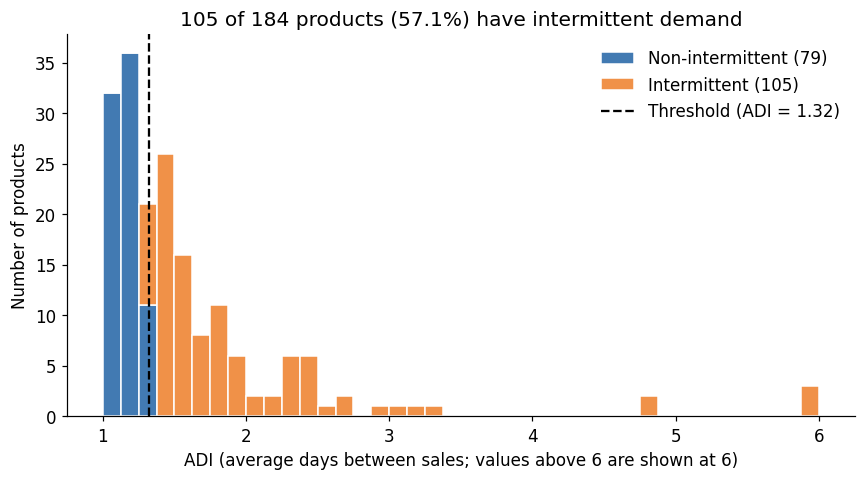

In [38]:
import numpy as np
import matplotlib.pyplot as plt

bins = np.linspace(1, 6, 41)
adi = quality.ADI.clip(upper=6)
is_int = quality.intermittent.astype(bool)
n_int = int(is_int.sum())

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist([adi[~is_int], adi[is_int]], bins=bins, stacked=True,
        color=["#427AB2", "#F09148"], edgecolor="white",
        label=[f"Non-intermittent ({len(quality) - n_int})", f"Intermittent ({n_int})"])
ax.axvline(1.32, color="black", linestyle="--", label="Threshold (ADI = 1.32)")
ax.set_xlabel("ADI (average days between sales; values above 6 are shown at 6)")
ax.set_ylabel("Number of products")
ax.set_title(f"{n_int} of {len(quality)} products ({100 * n_int / len(quality):.1f}%) have intermittent demand")
ax.legend(frameon=False)
plt.tight_layout(); plt.savefig("figures/fig1_adi_distribution.png", dpi=200); plt.show()

---
## Part 3: Features, Time Split and Model Comparison
### Design choices
- **Forecast horizon = 7 days.** Every lag or rolling feature uses data at least 7 days old, so a forecast made today never uses information from the future (no data leakage).
- **Time-based split, not random.** Data are split by date into training, calibration (180 days, used later for conformal intervals) and test (last 28 days).
- **Stock-out handling.** A run of 7 or more zero days that ends with a sale is treated as a likely stock-out, not true zero demand, and is excluded from training. Days without a price (item not on sale) are also excluded.

### Task 3.1: Build the long table and mark stock-outs
The wide table (one column per day) is reshaped into one row per product-day and merged with calendar and price information. The cell prints the share of suspected stock-out zeros and of not-listed days.

In [39]:
H = 7            # forecast horizon: all lag features use data at least 7 days old
CAL_LEN = 180    # calibration window (used later for conformal intervals)

long = sales.melt(id_vars=["item_id"], value_vars=day_cols, var_name="d", value_name="y")
long["t"] = long.d.str[2:].astype(int)
long = long.merge(calendar[["d", "date", "wm_yr_wk", "wday", "month", "event_name_1", "snap_CA"]], on="d", how="left")
long["date"] = pd.to_datetime(long["date"])
long = long.merge(prices[["item_id", "wm_yr_wk", "sell_price"]], on=["item_id", "wm_yr_wk"], how="left")
long = long.sort_values(["item_id", "t"]).reset_index(drop=True)
long["is_event"] = long.event_name_1.notna().astype(int)

def stockout_mask(y, item, min_run=7):
    """Mark runs of >= 7 zero days that are followed by a sale (likely stock-outs)."""
    zero = (y == 0); mask = np.zeros(len(y), bool); start = 0
    for i in range(1, len(y) + 1):
        if i == len(y) or item[i] != item[start]:
            seg = zero[start:i]; k = 0; n = len(seg)
            while k < n:
                if seg[k]:
                    j = k
                    while j < n and seg[j]: j += 1
                    if j - k >= min_run and j < n: mask[start + k:start + j] = True
                    k = j
                else:
                    k += 1
            start = i
    return mask

long["stockout_zero"] = stockout_mask(long.y.values, long.item_id.values)
long["not_listed"] = long.sell_price.isna()
print("Rows:", len(long))
print("Suspected stock-out zeros: %.1f%%" % (100 * long.stockout_zero.mean()))
print("Not-listed days: %.1f%%" % (100 * long.not_listed.mean()))

Rows: 357144
Suspected stock-out zeros: 9.6%
Not-listed days: 0.2%


### Task 3.2: Feature engineering and train / calibration / test split
| Feature group | Examples |
|---|---|
| Lags | sales 7, 14 and 28 days ago |
| Rolling statistics | 7- and 28-day mean and standard deviation, non-zero rate |
| Price | price, price relative to its recent median, price-change flag |
| Calendar | weekday, month, event flag, SNAP flag |
| Item | item code |

The split uses `cal_start` and `test_start` so that calibration data always come after training data, and test data come after both.

In [40]:
g = long.groupby("item_id")["y"]
for L in (7, 14, 28):
    long[f"lag{L}"] = g.shift(L)
long["_shifted"] = g.shift(H)
gs = long.groupby("item_id")["_shifted"]
for W in (7, 28):
    long[f"rmean{W}"] = gs.rolling(W, min_periods=1).mean().reset_index(level=0, drop=True)
    long[f"rstd{W}"] = gs.rolling(W, min_periods=2).std().reset_index(level=0, drop=True)
long["_nz"] = (long["_shifted"] > 0).astype(float).where(long["_shifted"].notna())
long["nz_rate28"] = long.groupby("item_id")["_nz"].rolling(28, min_periods=1).mean().reset_index(level=0, drop=True)
long["price_ref"] = long.groupby("item_id")["sell_price"].rolling(28, min_periods=1).median().reset_index(level=0, drop=True)
long["price_ref"] = long.groupby("item_id")["price_ref"].shift(1)
long["price_ratio"] = long.sell_price / long.price_ref
long["price_change"] = ((long.price_ratio - 1).abs() > 0.02).astype(int)
long["item_code"] = long.item_id.astype("category").cat.codes

FEATS = ["lag7", "lag14", "lag28", "rmean7", "rmean28", "rstd7", "rstd28", "nz_rate28",
         "sell_price", "price_ratio", "price_change", "wday", "month", "is_event", "snap_CA", "item_code"]

test_start = n_days - TEST_LEN + 1
cal_start = test_start - CAL_LEN
ok = ~long.stockout_zero & ~long.not_listed
train = long[(long.t < cal_start) & ok].dropna(subset=["lag28"]).copy()
calib = long[(long.t >= cal_start) & (long.t < test_start) & ok].dropna(subset=["lag28"]).copy()
test = long[long.t >= test_start].copy()
print("Train rows:", len(train), "| Calibration rows:", len(calib), "| Test rows:", len(test))

Train rows: 284066 | Calibration rows: 29556 | Test rows: 5152


### Task 3.3: Train three models and compare them
| Model | Role |
|---|---|
| Seasonal Naive(7) | Baseline: same weekday last week |
| Linear Regression | Simple model from the course |
| LightGBM | Main model: gradient-boosted decision trees |

**Metrics**
- **RMSE** and **MAE** are measured in units sold, so high-volume products influence them most.
- **RMSSE** scales each product's error by its own volatility and then averages, so every product counts equally.

**In our run:**

| Model | RMSE | MAE | RMSSE |
|---|---|---|---|
| Seasonal Naive(7) | 3.682 | 2.162 | 0.878 |
| Linear Regression | 3.059 | 1.965 | 0.764 |
| LightGBM | 3.210 | 2.103 | 0.723 |

Both learned models clearly beat the baseline. Linear regression is best on RMSE and MAE, LightGBM is best on RMSSE, so no model wins on every metric.

In [41]:
import lightgbm as lgb
from sklearn.linear_model import LinearRegression

# Model 1: Seasonal Naive(7) = same weekday last week
for d in (calib, test):
    d["pred_naive"] = d["lag7"]

# Model 2: Linear Regression (simple model taught in the course)
LR_FEATS = [f for f in FEATS if f != "item_code"]
fill = train[LR_FEATS].median()
lr = LinearRegression().fit(train[LR_FEATS].fillna(fill), train.y)

# Model 3: LightGBM (main model)
gbm = lgb.LGBMRegressor(n_estimators=600, learning_rate=0.05, num_leaves=63, subsample=0.8,
                        colsample_bytree=0.8, subsample_freq=1, random_state=42, verbose=-1)
gbm.fit(train[FEATS], train.y)

for d in (calib, test):
    d["pred_lr"] = np.clip(lr.predict(d[LR_FEATS].fillna(fill)), 0, None)
    d["pred_gbm"] = np.clip(gbm.predict(d[FEATS]), 0, None)

scale = train.groupby("item_id")["y"].apply(lambda s: np.mean(np.diff(s.values) ** 2)).replace(0, np.nan)
def evaluate(df, col):
    e = df.y - df[col]
    rmsse = np.sqrt(((e ** 2).groupby(df.item_id).mean() / scale.reindex(df.item_id.unique())).mean())
    return pd.Series({"RMSE": np.sqrt((e ** 2).mean()), "MAE": e.abs().mean(), "RMSSE": rmsse})

t_eval = test.dropna(subset=["pred_naive"])
results = pd.DataFrame({
    "Seasonal Naive(7)": evaluate(t_eval, "pred_naive"),
    "Linear Regression": evaluate(t_eval, "pred_lr"),
    "LightGBM": evaluate(t_eval, "pred_gbm"),
}).T
print(results.round(3))
results.to_csv("overall_metrics.csv")

                    RMSE    MAE  RMSSE
Seasonal Naive(7)  3.682  2.162  0.878
Linear Regression  3.059  1.965  0.764
LightGBM           3.210  2.103  0.723


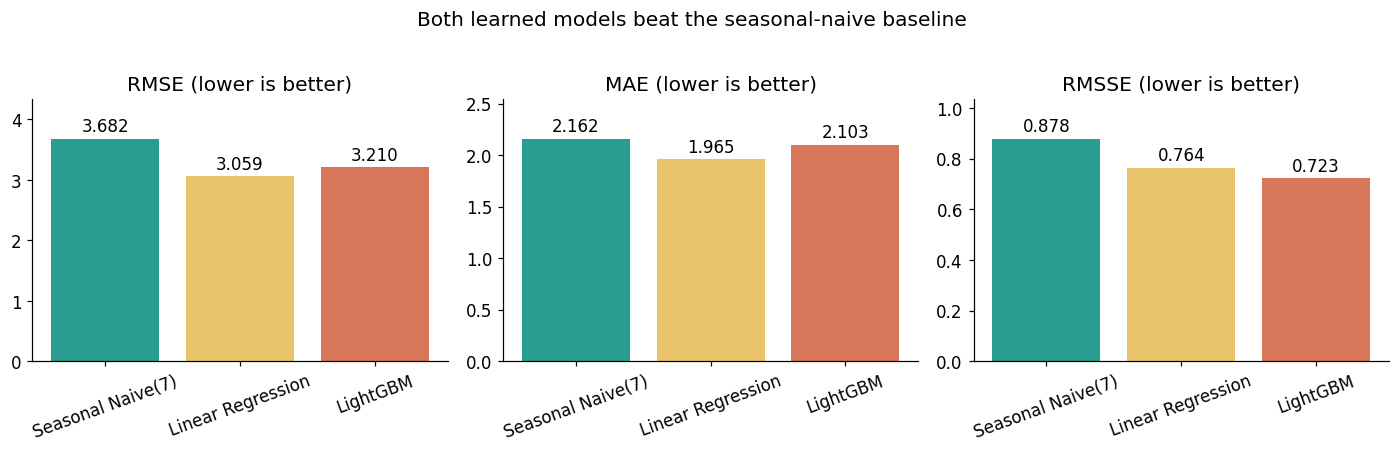

In [42]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, metric in zip(axes, ["RMSE", "MAE", "RMSSE"]):
    vals = results[metric]
    bars = ax.bar(vals.index, vals.values, color=[COLORS[m] for m in vals.index])
    ax.bar_label(bars, fmt="%.3f", padding=2)
    ax.set_title(metric + " (lower is better)")
    ax.set_ylim(0, vals.max() * 1.18)
    ax.tick_params(axis="x", rotation=20)
fig.suptitle("Both learned models beat the seasonal-naive baseline", y=1.02)
plt.tight_layout(); plt.savefig("figures/fig2_model_comparison.png", dpi=200, bbox_inches="tight"); plt.show()

---
## Part 4: Stratified Evaluation
A single overall score hides *where* the model is weak. We therefore split the test errors by scenario and by product type.

### Task 4.1: Error by scenario
Scenarios: normal day, weekend, holiday/event, SNAP day and price-change day. Values are RMSE (lower is better).

**In our run:** weekends are the hardest scenario and normal days the easiest. Linear regression is best on normal and SNAP days; LightGBM is best on holidays (3.682) and price-change days (2.532). Price-change days contain only 49 observations, so that result is only indicative.

In [43]:
def define_strata(df):
    return {
        "All days": df.index == df.index,
        "Normal day": (df.is_event == 0) & (df.snap_CA == 0) & (df.price_change == 0) & (df.wday > 2),
        "Weekend": df.wday <= 2,
        "Holiday/event": df.is_event == 1,
        "SNAP day": df.snap_CA == 1,
        "Price-change day": df.price_change == 1,
    }

models = {"Seasonal Naive(7)": "pred_naive", "Linear Regression": "pred_lr", "LightGBM": "pred_gbm"}
rows = []
for name, mask in define_strata(t_eval).items():
    sub = t_eval[mask]
    row = {"Stratum": name, "n": len(sub)}
    for mname, col in models.items():
        row["RMSE " + mname] = np.sqrt(((sub.y - sub[col]) ** 2).mean())
    rows.append(row)
strat = pd.DataFrame(rows).set_index("Stratum")
print(strat.round(3).to_string())
strat.to_csv("stratified_errors.csv")

                     n  RMSE Seasonal Naive(7)  RMSE Linear Regression  RMSE LightGBM
Stratum                                                                              
All days          5152                   3.682                   3.059          3.210
Normal day        2364                   3.514                   2.852          3.018
Weekend           1472                   4.096                   3.547          3.578
Holiday/event      736                   4.083                   3.836          3.682
SNAP day          1840                   3.697                   3.183          3.327
Price-change day    49                   3.084                   2.716          2.532


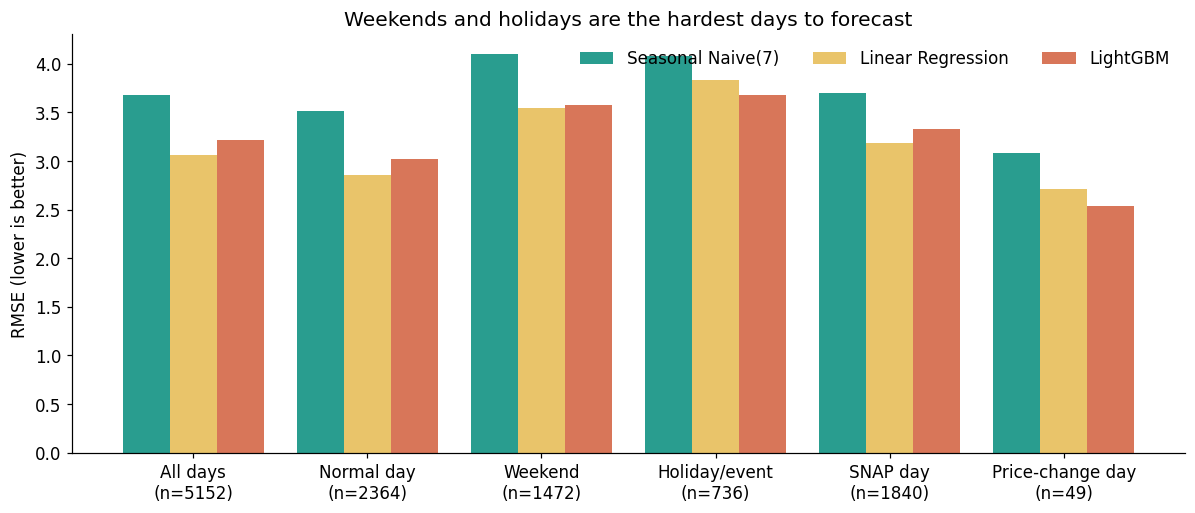

In [44]:
import numpy as np
cols = {"Seasonal Naive(7)": "RMSE Seasonal Naive(7)", "Linear Regression": "RMSE Linear Regression", "LightGBM": "RMSE LightGBM"}
x = np.arange(len(strat)); w = 0.27
fig, ax = plt.subplots(figsize=(11, 4.8))
for i, (m, c) in enumerate(cols.items()):
    ax.bar(x + (i - 1) * w, strat[c].values, w, label=m, color=COLORS[m])
ax.set_xticks(x)
ax.set_xticklabels([f"{s}\n(n={int(n)})" for s, n in zip(strat.index, strat["n"])])
ax.set_ylabel("RMSE (lower is better)")
ax.set_title("Weekends and holidays are the hardest days to forecast")
ax.legend(frameon=False, ncol=3)
plt.tight_layout(); plt.savefig("figures/fig3_error_by_scenario.png", dpi=200); plt.show()

### Task 4.2: Error by product type
Products are grouped (a) by intermittent vs. non-intermittent demand and (b) into low / mid / high average sales volume (three equal-sized groups).

**In our run:**
- Low volume: LightGBM is best on all three metrics.
- Mid volume: the two models are almost tied.
- High volume: linear regression is best on all three metrics.
- For intermittent products, the seasonal-naive baseline has the lowest MAE because many days are zero.

This suggests that the best model depends on the type of product, which motivates the exploratory router in Part 8.

In [45]:
t_eval = t_eval.copy()
t_eval["intermittent"] = t_eval.item_id.map(quality.set_index("item_id").intermittent)
item_mean = train.groupby("item_id").y.mean()
t_eval["volume_group"] = pd.qcut(t_eval.item_id.map(item_mean), 3, labels=["Low volume", "Mid volume", "High volume"])

def group_table(col):
    out = []
    for key, sub in t_eval.groupby(col, observed=True):
        for mname, mcol in models.items():
            r = evaluate(sub, mcol)
            out.append({"Group": key, "Model": mname, "Items": sub.item_id.nunique(), **r.round(3).to_dict()})
    return pd.DataFrame(out)

by_int = group_table("intermittent")
by_vol = group_table("volume_group")
print(by_int.to_string(index=False)); print()
print(by_vol.to_string(index=False))
by_int.to_csv("errors_by_intermittent.csv", index=False)
by_vol.to_csv("errors_by_volume.csv", index=False)

 Group             Model  Items  RMSE   MAE  RMSSE
     0 Seasonal Naive(7)     79 4.910 3.255  0.895
     0 Linear Regression     79 4.113 2.723  0.707
     0          LightGBM     79 4.260 2.975  0.698
     1 Seasonal Naive(7)    105 2.370 1.339  0.865
     1 Linear Regression    105 1.916 1.394  0.804
     1          LightGBM    105 2.098 1.446  0.740

      Group             Model  Items  RMSE   MAE  RMSSE
 Low volume Seasonal Naive(7)     62 1.578 1.005  0.913
 Low volume Linear Regression     62 1.421 1.152  0.902
 Low volume          LightGBM     62 1.287 0.986  0.780
 Mid volume Seasonal Naive(7)     61 2.756 1.888  0.903
 Mid volume Linear Regression     61 2.138 1.626  0.712
 Mid volume          LightGBM     61 2.097 1.587  0.711
High volume Seasonal Naive(7)     61 5.546 3.611  0.815
High volume Linear Regression     61 4.648 3.130  0.653
High volume          LightGBM     61 5.000 3.754  0.672


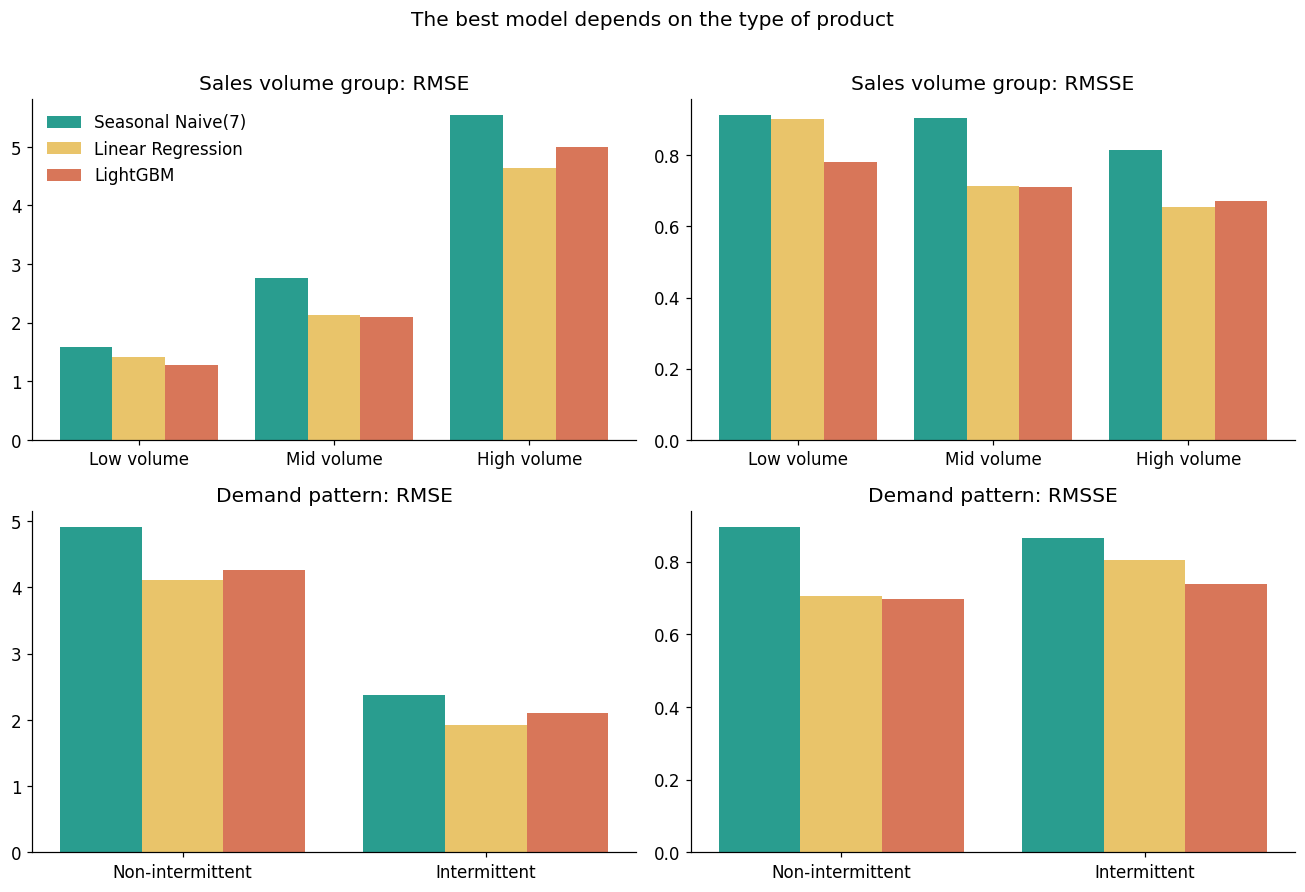

In [46]:
import numpy as np
vol_order = ["Low volume", "Mid volume", "High volume"]
int_names = {0: "Non-intermittent", 1: "Intermittent"}
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for row, (tbl, order, title) in enumerate([
        (by_vol, vol_order, "Sales volume group"),
        (by_int.assign(Group=by_int.Group.map(int_names)), list(int_names.values()), "Demand pattern")]):
    for col, metric in enumerate(["RMSE", "RMSSE"]):
        ax = axes[row, col]
        pv = tbl.pivot(index="Group", columns="Model", values=metric).reindex(order)
        x = np.arange(len(pv)); w = 0.27
        for i, m in enumerate(["Seasonal Naive(7)", "Linear Regression", "LightGBM"]):
            ax.bar(x + (i - 1) * w, pv[m].values, w, label=m, color=COLORS[m])
        ax.set_xticks(x); ax.set_xticklabels(pv.index)
        ax.set_title(f"{title}: {metric}")
        if row == 0 and col == 0: ax.legend(frameon=False)
fig.suptitle("The best model depends on the type of product", y=1.01)
plt.tight_layout(); plt.savefig("figures/fig4_error_by_product_type.png", dpi=200, bbox_inches="tight"); plt.show()

---
## Part 5: Prediction Intervals and Anomaly Alerting
### Task 5.1: Conformal Prediction Intervals
A point forecast ("we expect to sell 50") says nothing about risk. **Split conformal prediction** adds a range around each forecast with a guaranteed long-run coverage.

**How it works**
1. Take the model's absolute errors on the calibration window.
2. For a 90% interval, take the error value that 90% of calibration errors fall below.
3. Add and subtract this value from every forecast.

Errors grow with sales volume, so we calibrate separately for three volume groups (low, mid, high). The method needs no retraining and works with any model.

**What to check:** coverage (the share of actual values inside the interval, target 0.90) and average interval width.

**In our run:** half-widths are about 1.83 / 3.17 / 7.39 units for low / mid / high volume. Overall coverage is 0.895. Coverage is lower on weekends (0.852) and holidays (0.879), which means intervals are too narrow on those days.

In [47]:
ALPHA = 0.10   # target: 90% of actual values should fall inside the interval

# Group items by average sales volume (3 groups), so each group gets its own interval width
item_mean = train.groupby("item_id").y.mean()
vol_group = pd.qcut(item_mean, 3, labels=[0, 1, 2])
for d in (calib, test):
    d["vgrp"] = d.item_id.map(vol_group).astype(int)

# Calibration: absolute errors of LightGBM on the calibration window
calib["score"] = (calib.y - calib.pred_gbm).abs()

def conformal_q(s, alpha=ALPHA):
    n = len(s); k = min(int(np.ceil((n + 1) * (1 - alpha))), n)
    return np.sort(s.values)[k - 1]

q = calib.groupby("vgrp")["score"].apply(conformal_q)
print("Interval half-width per volume group (low, mid, high):", q.round(2).tolist())

test["q"] = test.vgrp.map(q)
test["lo"] = (test.pred_gbm - test.q).clip(lower=0)
test["hi"] = test.pred_gbm + test.q
test["covered"] = ((test.y >= test.lo) & (test.y <= test.hi)).astype(int)

rows = []
for name, mask in define_strata(test).items():
    sub = test[mask]
    rows.append({"Stratum": name, "n": len(sub), "Coverage": sub.covered.mean(), "Avg width": (sub.hi - sub.lo).mean()})
cov = pd.DataFrame(rows).set_index("Stratum")
print("Target coverage:", 1 - ALPHA)
print(cov.round(3).to_string())
cov.to_csv("conformal_coverage.csv")

Interval half-width per volume group (low, mid, high): [1.83, 3.17, 7.39]
Target coverage: 0.9
                     n  Coverage  Avg width
Stratum                                    
All days          5152     0.895      7.141
Normal day        2364     0.915      6.936
Weekend           1472     0.852      7.518
Holiday/event      736     0.879      7.360
SNAP day          1840     0.894      7.283
Price-change day    49     0.878      3.863


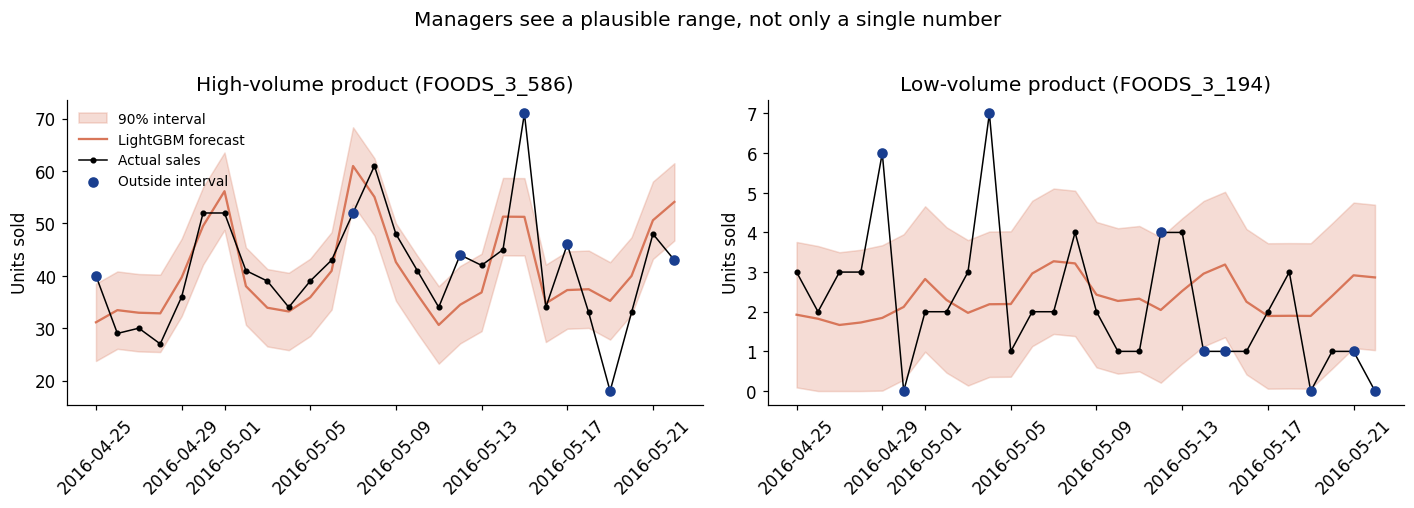

In [48]:
hi_item = test.groupby("item_id").y.sum().idxmax()
low_pool = test[test.vgrp == 0].groupby("item_id").y.apply(lambda s: (s > 0).sum())
lo_item = low_pool.idxmax()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True)
for ax, item, label in [(axes[0], hi_item, "High-volume product"), (axes[1], lo_item, "Low-volume product")]:
    s = test[test.item_id == item].sort_values("t")
    ax.fill_between(s.date, s.lo, s.hi, color=COLORS["LightGBM"], alpha=0.25, label="90% interval")
    ax.plot(s.date, s.pred_gbm, color=COLORS["LightGBM"], label="LightGBM forecast")
    ax.plot(s.date, s.y, "ko-", markersize=3, linewidth=1, label="Actual sales")
    outside = s[(s.y > s.hi) | (s.y < s.lo)]
    ax.scatter(outside.date, outside.y, color="#193E8F", zorder=5, s=35, label="Outside interval")
    ax.set_title(f"{label} ({item})"); ax.set_ylabel("Units sold"); ax.tick_params(axis="x", rotation=45)
axes[0].legend(frameon=False, fontsize=9)
fig.suptitle("Managers see a plausible range, not only a single number", y=1.02)
plt.tight_layout(); plt.savefig("figures/fig5_prediction_interval_example.png", dpi=200, bbox_inches="tight"); plt.show()

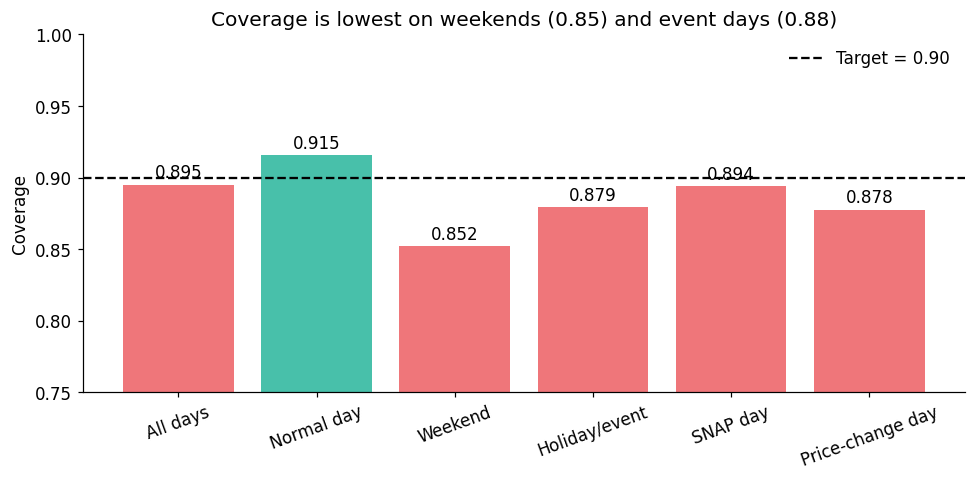

In [49]:
fig, ax = plt.subplots(figsize=(9, 4.5))
colors = ["#48C0AA" if v >= 0.90 else "#EF767A" for v in cov["Coverage"]]
bars = ax.bar(cov.index, cov["Coverage"], color=colors)
ax.bar_label(bars, fmt="%.3f", padding=2)
ax.axhline(0.90, color="black", linestyle="--", label="Target = 0.90")
ax.set_ylim(0.75, 1.0); ax.set_ylabel("Coverage")
ax.set_title("Coverage is lowest on weekends (0.85) and event days (0.88)")
ax.tick_params(axis="x", rotation=20); ax.legend(frameon=False, loc="upper right")
plt.tight_layout(); plt.savefig("figures/fig6_coverage_by_scenario.png", dpi=200); plt.show()

### Task 5.2: Anomaly Alerting
**Goal:** raise an alert when actual sales differ strongly from what the model expected.

**Important:** real M5 data contain no anomaly labels. To measure detection quality we **inject synthetic anomalies** into 5% of test rows: half are demand surges (actual sales x 2.5, rounded) and half are drops to zero. Results therefore show how well each rule can find *simulated* anomalies, not real events.

| Rule | Idea |
|---|---|
| Interval | Alert if the actual value falls outside the 90% interval |
| z-score | Alert if the standardized error exceeds 3 |
| EWMA | Alert on a smoothed, persistent drift of the error |
| CUSUM | Alert when small errors accumulate in one direction |

**In our run:**

| Rule | Recall | Precision | False alarm rate |
|---|---|---|---|
| Interval | 0.409 | 0.168 | 0.106 |
| z-score | 0.198 | 0.443 | 0.013 |
| EWMA | 0.144 | 0.120 | 0.056 |
| CUSUM | 0.156 | 0.175 | 0.039 |

The interval rule finds the most anomalies but gives the most false alarms; z-score is the most precise but misses more. EWMA and CUSUM are designed for sustained drifts, so they are weaker against single-day spikes.

**Caveats:** (1) The four rules use different thresholds, so they sit at different false-alarm levels (about 10% for the interval rule vs. about 1% for z-score); recall and precision are therefore not directly comparable. (2) Anomalies are injected only where actual sales > 0; surges on products selling 1-2 units and drops to zero on slow products are almost indistinguishable from normal demand, which caps recall for every rule. (3) Only 5% of rows are positive (257 of 5152), which lowers precision.

In [50]:
rng = np.random.default_rng(42)
a = test.sort_values(["item_id", "t"]).reset_index(drop=True).copy()

a["label"] = 0
cand = a.index[a.y > 0].to_numpy()
pick = rng.choice(cand, int(0.05 * len(a)), replace=False)
a.loc[pick, "label"] = 1
surge = rng.random(len(a)) < 0.5

a["yobs"] = a.y.astype(float)
a.loc[(a.label == 1) & surge, "yobs"] = (a.y * 2.5).round()
a.loc[(a.label == 1) & ~surge, "yobs"] = 0

sd = (calib.y - calib.pred_gbm).groupby(calib.item_id).std().fillna((calib.y - calib.pred_gbm).std())
a["z"] = (a.yobs - a.pred_gbm) / a.item_id.map(sd).replace(0, np.nan).fillna(1)

a["alert_interval"] = ((a.yobs > a.hi) | (a.yobs < a.lo)).astype(int)
a["alert_z"] = (a.z.abs() > 3).astype(int)
a["ewma"] = a.groupby("item_id").z.transform(lambda s: s.ewm(alpha=0.3).mean())
a["alert_ewma"] = (a.ewma.abs() > 1.5).astype(int)

def cusum_alerts(s, k=0.5, h=4):
    pos = neg = 0
    out = []
    for v in s.values:
        pos = max(0, pos + v - k)
        neg = max(0, neg - v - k)
        hit = int(pos > h or neg > h)
        out.append(hit)
        if hit:
            pos = neg = 0
    return pd.Series(out, index=s.index)

a["alert_cusum"] = a.groupby("item_id").z.transform(cusum_alerts)

from sklearn.metrics import confusion_matrix
res = {}
for name in ["alert_interval", "alert_z", "alert_ewma", "alert_cusum"]:
    tn, fp, fn, tp = confusion_matrix(a.label, a[name], labels=[0, 1]).ravel()
    res[name] = {"TP": tp, "FP": fp, "FN": fn, "TN": tn,
                 "Recall": tp / max(tp + fn, 1), "Precision": tp / max(tp + fp, 1),
                 "False alarm rate": fp / max(fp + tn, 1)}
anom = pd.DataFrame(res).T
print(anom.round(3).to_string())
anom.to_csv("anomaly_eval.csv")

# Alerts on the actual series, used only by the Part 6 simulation
a["alert_true"] = ((a.y > a.hi) | (a.y < a.lo)).astype(int)

                   TP     FP     FN      TN  Recall  Precision  False alarm rate
alert_interval  105.0  519.0  152.0  4376.0   0.409      0.168             0.106
alert_z          51.0   64.0  206.0  4831.0   0.198      0.443             0.013
alert_ewma       37.0  272.0  220.0  4623.0   0.144      0.120             0.056
alert_cusum      40.0  189.0  217.0  4706.0   0.156      0.175             0.039


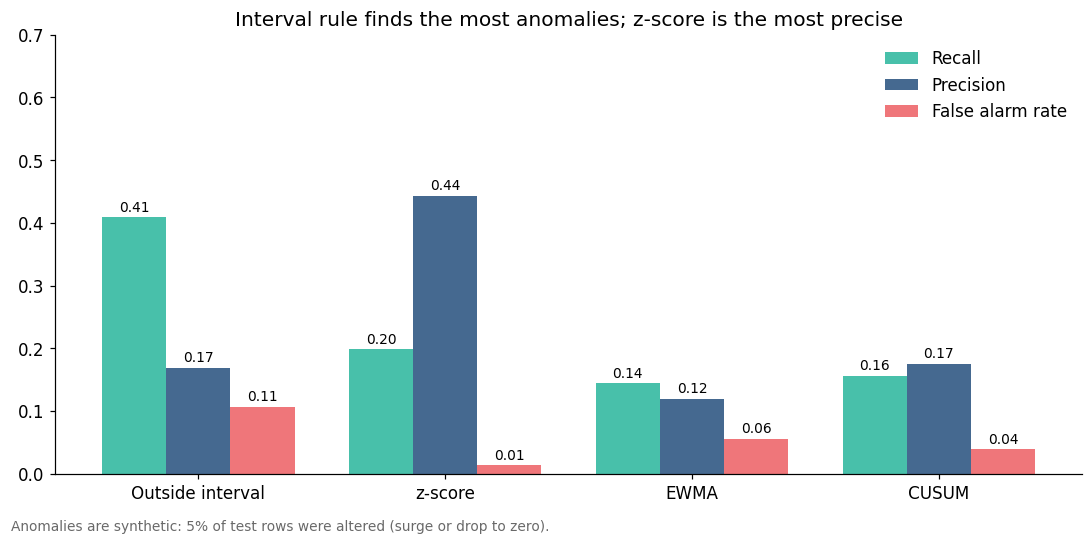

In [51]:
import numpy as np
an = anom[["Recall", "Precision", "False alarm rate"]].astype(float)
an.index = ["Outside interval", "z-score", "EWMA", "CUSUM"]
x = np.arange(len(an)); w = 0.26
fig, ax = plt.subplots(figsize=(10, 4.8))
for i, (c, colr) in enumerate(zip(an.columns, METRIC_COLORS)):
    bars = ax.bar(x + (i - 1) * w, an[c].values, w, label=c, color=colr)
    ax.bar_label(bars, fmt="%.2f", padding=2, fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(an.index); ax.set_ylim(0, 0.7)
ax.set_title("Interval rule finds the most anomalies; z-score is the most precise")
ax.legend(frameon=False)
fig.text(0.01, -0.02, "Anomalies are synthetic: 5% of test rows were altered (surge or drop to zero).", fontsize=9, color="dimgray")
plt.tight_layout(); plt.savefig("figures/fig7_anomaly_detection.png", dpi=200, bbox_inches="tight"); plt.show()

---
## Part 6: Replenishment Simulation
### Task 6.1: From forecast to decision
We compare four ways of choosing how much stock to prepare for each product-day:

| Policy | Stock level |
|---|---|
| P1 | Point forecast |
| P2 | Point forecast + one standard deviation of calibration errors (fixed safety stock) |
| P3 | Upper end of the 90% conformal interval |
| P4 | P3, plus 20% extra for 7 days after the actual sales fell outside the 90% interval (uses past days only; these alerts are not the synthetic anomalies of Part 5b) |

**Metrics:** fill rate (share of demand met), share of days with a stock-out, and average overstock in units.

**Replenishment priority:** `(upper bound - forecast) x price` highlights products with the widest uncertainty and highest value at risk. Because products in the same volume group share the same interval width, this score is effectively (group width x price), so ties are common and it does not capture item-specific uncertainty.

**Simplifications:** no order lead time, no inventory carry-over between days, stock levels are not rounded to whole units, the simulation uses the actual (un-injected) sales, and test-window zeros caused by real stock-outs are not removed, so true demand may be slightly under-estimated.

**In our run:**

| Policy | Fill rate | Stockout days % | Avg overstock | Total cost (illustrative) |
|---|---|---|---|---|
| P1 | 0.777 | 36.4 | 1.28 | 19346 |
| P2 | 0.931 | 12.2 | 3.21 | 20447 |
| P3 | 0.963 | 5.9 | 4.71 | 26353 |
| P4 | 0.977 | 4.1 | 5.35 | 28886 |

A higher fill rate always comes with more overstock. The biggest gain comes from adding a basic safety stock (P1 to P2).

In [52]:
a["recent_alert"] = a.groupby("item_id").alert_true.transform(
    lambda s: s.shift(1).rolling(7, min_periods=1).max().fillna(0))

a["stock_P1"] = a.pred_gbm
a["stock_P2"] = a.pred_gbm + a.item_id.map(sd).fillna(sd.mean())
a["stock_P3"] = a.hi
a["stock_P4"] = np.where(a.recent_alert == 1, a.hi * 1.2, a.hi)

COST_SHORT, COST_OVER = 3.0, 1.0      # illustrative assumption, NOT from data
names = {"stock_P1": "P1 Point forecast", "stock_P2": "P2 Forecast + safety stock",
         "stock_P3": "P3 Conformal upper bound", "stock_P4": "P4 Upper bound + alert uplift"}

rows = []
for col, label in names.items():
    short = (a.y - a[col]).clip(lower=0)
    over = (a[col] - a.y).clip(lower=0)
    rows.append({"Policy": label,
                 "Fill rate": 1 - short.sum() / a.y.sum(),
                 "Stockout days (%)": 100 * (short > 0).mean(),
                 "Avg overstock units": over.mean(),
                 "Total cost (illustrative)": COST_SHORT * short.sum() + COST_OVER * over.sum()})
sim = pd.DataFrame(rows).set_index("Policy")
print(sim.round(3).to_string())
sim.to_csv("replenishment_sim.csv")

a["risk_priority"] = (a.hi - a.pred_gbm) * a.sell_price.fillna(0)
top = a.groupby("item_id").risk_priority.mean().sort_values(ascending=False).head(10)
print("\nTop 10 items by replenishment risk priority")
print(top.round(2).to_string())
top.to_csv("top10_risk_items.csv")

                               Fill rate  Stockout days (%)  Avg overstock units  Total cost (illustrative)
Policy                                                                                                     
P1 Point forecast                  0.777             36.432                1.276                  19346.248
P2 Forecast + safety stock         0.931             12.209                3.207                  20446.873
P3 Conformal upper bound           0.963              5.881                4.709                  26353.335
P4 Upper bound + alert uplift      0.977              4.134                5.353                  28885.673

Top 10 items by replenishment risk priority
item_id
FOODS_3_546    44.18
FOODS_3_574    44.18
FOODS_3_476    44.18
FOODS_3_534    36.05
FOODS_3_202    34.58
FOODS_3_136    34.58
FOODS_3_704    34.58
FOODS_3_156    30.88
FOODS_3_473    30.88
FOODS_3_695    29.40


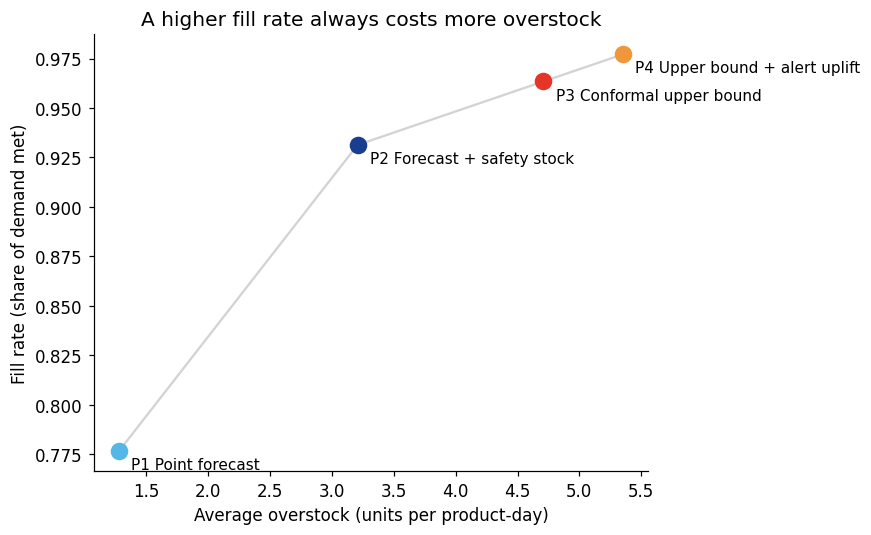

In [53]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(sim["Avg overstock units"], sim["Fill rate"], "-", color="lightgray", zorder=1)
for pol, r in sim.iterrows():
    key = pol.split(" ")[0]
    ax.scatter(r["Avg overstock units"], r["Fill rate"], s=110, color=POLICY_COLORS[key], zorder=2)
    ax.annotate(pol, (r["Avg overstock units"], r["Fill rate"]), textcoords="offset points", xytext=(8, -12), fontsize=10)
ax.set_xlabel("Average overstock (units per product-day)")
ax.set_ylabel("Fill rate (share of demand met)")
ax.set_title("A higher fill rate always costs more overstock")
plt.tight_layout(); plt.savefig("figures/fig8_tradeoff_fill_vs_overstock.png", dpi=200); plt.show()

### Task 6.2: Cost sensitivity
Which policy is "best" depends on how costly a stock-out is compared with a spare unit. The cost ratio used here is an **illustrative assumption, not estimated from data**. We recompute total cost for ratios from 1 to 20.

**In our run:** point forecast is cheapest at ratios 1-3, forecast plus safety stock at ratios 5-10, and the upper bound with alert uplift only at ratio 20. Conformal intervals are therefore most valuable where stock-outs are very costly, for example short-shelf-life fresh goods.

In [54]:
rows = []
for ratio in [1, 2, 3, 5, 10, 20]:
    row = {"Shortage/overstock cost ratio": ratio}
    for col, label in names.items():
        short = (a.y - a[col]).clip(lower=0).sum()
        over = (a[col] - a.y).clip(lower=0).sum()
        row[label] = ratio * short + over
    rows.append(row)
sens = pd.DataFrame(rows).set_index("Shortage/overstock cost ratio")
sens["Cheapest policy"] = sens.idxmin(axis=1)
print(sens.round(0).to_string())
sens.to_csv("cost_sensitivity.csv")

                               P1 Point forecast  P2 Forecast + safety stock  P3 Conformal upper bound  P4 Upper bound + alert uplift                Cheapest policy
Shortage/overstock cost ratio                                                                                                                                       
1                                        10832.0                     17831.0                   24959.0                        28014.0              P1 Point forecast
2                                        15089.0                     19139.0                   25656.0                        28450.0              P1 Point forecast
3                                        19346.0                     20447.0                   26353.0                        28886.0              P1 Point forecast
5                                        27860.0                     23063.0                   27748.0                        29757.0     P2 Forecast + safety stock
10        

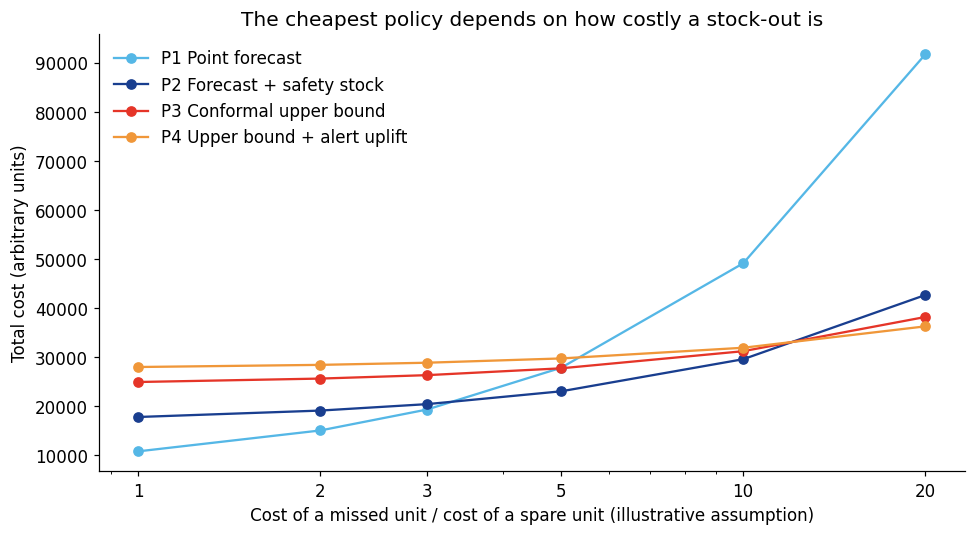

In [55]:
fig, ax = plt.subplots(figsize=(9, 5))
sens_plot = sens.drop(columns=["Cheapest policy"])
for pol in sens_plot.columns:
    ax.plot(sens_plot.index, sens_plot[pol], marker="o", label=pol, color=POLICY_COLORS[pol.split(" ")[0]])
ax.set_xscale("log"); ax.set_xticks(sens_plot.index); ax.set_xticklabels(sens_plot.index)
ax.set_xlabel("Cost of a missed unit / cost of a spare unit (illustrative assumption)")
ax.set_ylabel("Total cost (arbitrary units)")
ax.set_title("The cheapest policy depends on how costly a stock-out is")
ax.legend(frameon=False)
plt.tight_layout(); plt.savefig("figures/fig9_cost_sensitivity.png", dpi=200); plt.show()

---
## Part 7: Rolling-Origin Validation
All results so far come from one 28-day test window. To check that they are not a coincidence, we repeat the whole procedure on **five consecutive 28-day windows**, moving backwards in time. For each window, the models and conformal intervals are re-trained using only data from before that window.

**In our run (5-fold mean, standard deviation in brackets):**

| | Naive | Linear Regression | LightGBM |
|---|---|---|---|
| RMSE | 3.698 (0.097) | 3.069 (0.085) | 3.164 (0.191) |
| RMSSE | 0.859 (0.021) | 0.743 (0.014) | 0.692 (0.023) |

Conformal coverage averages 0.903 (std 0.010). Both learned models beat the baseline in every window; LightGBM has the best RMSSE in all five windows, while linear regression has the best RMSE in three of five.

**Limitation:** all five windows lie between January and May 2016, so full-year seasonality is not tested. Earlier windows also have less training data.

In [56]:
from sklearn.linear_model import LinearRegression
import lightgbm as lgb
N_FOLDS = 5   # 5 rolling windows of 28 days, moving backwards from the end of the data
LR_FEATS = [f for f in FEATS if f != "item_code"]
ok_all = ~long.stockout_zero & ~long.not_listed
rows = []
for k in range(N_FOLDS):
    te_start = n_days - TEST_LEN * (k + 1) + 1
    te_end = te_start + TEST_LEN - 1
    ca_start = te_start - CAL_LEN
    tr = long[(long.t < ca_start) & ok_all].dropna(subset=["lag28"]).copy()
    ca = long[(long.t >= ca_start) & (long.t < te_start) & ok_all].dropna(subset=["lag28"]).copy()
    te = long[(long.t >= te_start) & (long.t <= te_end)].dropna(subset=["lag7"]).copy()

    fill_k = tr[LR_FEATS].median()
    lr_k = LinearRegression().fit(tr[LR_FEATS].fillna(fill_k), tr.y)
    gbm_k = lgb.LGBMRegressor(n_estimators=600, learning_rate=0.05, num_leaves=63, subsample=0.8,
                              colsample_bytree=0.8, subsample_freq=1, random_state=42, verbose=-1)
    gbm_k.fit(tr[FEATS], tr.y)
    for d in (ca, te):
        d["p_naive"] = d["lag7"]
        d["p_lr"] = np.clip(lr_k.predict(d[LR_FEATS].fillna(fill_k)), 0, None)
        d["p_gbm"] = np.clip(gbm_k.predict(d[FEATS]), 0, None)

    sc = tr.groupby("item_id")["y"].apply(lambda s: np.mean(np.diff(s.values) ** 2)).replace(0, np.nan)
    def ev(df, col):
        e = df.y - df[col]
        rmsse = np.sqrt(((e ** 2).groupby(df.item_id).mean() / sc.reindex(df.item_id.unique())).mean())
        return np.sqrt((e ** 2).mean()), rmsse

    # Conformal coverage for this fold (volume-group calibration, as before)
    vg = pd.qcut(tr.groupby("item_id").y.mean(), 3, labels=[0, 1, 2])
    ca["vg"] = ca.item_id.map(vg).astype(int); te["vg"] = te.item_id.map(vg).astype(int)
    ca["score"] = (ca.y - ca.p_gbm).abs()
    qk = ca.groupby("vg")["score"].apply(lambda s: np.sort(s.values)[min(int(np.ceil((len(s) + 1) * 0.9)), len(s)) - 1])
    qq = te.vg.map(qk)
    cover = ((te.y >= te.p_gbm - qq) & (te.y <= te.p_gbm + qq)).mean()

    row = {"Fold": k + 1, "Test window (d_)": f"{te_start}-{te_end}", "Test start date": te.date.min().date()}
    for nm, col in [("Naive", "p_naive"), ("LinReg", "p_lr"), ("LightGBM", "p_gbm")]:
        r, s = ev(te, col)
        row["RMSE " + nm] = r; row["RMSSE " + nm] = s
    row["Conformal coverage"] = cover
    rows.append(row)
    print("fold", k + 1, "done", flush=True)

cv = pd.DataFrame(rows).set_index("Fold")
print(cv.round(3).to_string())
num = cv.select_dtypes("number")
summary = pd.DataFrame({"mean": num.mean(), "std": num.std()})
print(); print(summary.round(3).to_string())
cv.to_csv("rolling_cv_by_fold.csv"); summary.to_csv("rolling_cv_summary.csv")

fold 1 done
fold 2 done
fold 3 done
fold 4 done
fold 5 done
     Test window (d_) Test start date  RMSE Naive  RMSSE Naive  RMSE LinReg  RMSSE LinReg  RMSE LightGBM  RMSSE LightGBM  Conformal coverage
Fold                                                                                                                                        
1           1914-1941      2016-04-25       3.682        0.878        3.059         0.764          3.210           0.723               0.895
2           1886-1913      2016-03-28       3.560        0.842        2.967         0.736          3.168           0.685               0.894
3           1858-1885      2016-02-29       3.685        0.863        3.014         0.743          2.995           0.689               0.910
4           1830-1857      2016-02-01       3.828        0.878        3.128         0.746          3.457           0.705               0.901
5           1802-1829      2016-01-04       3.736        0.833        3.178         0.727     

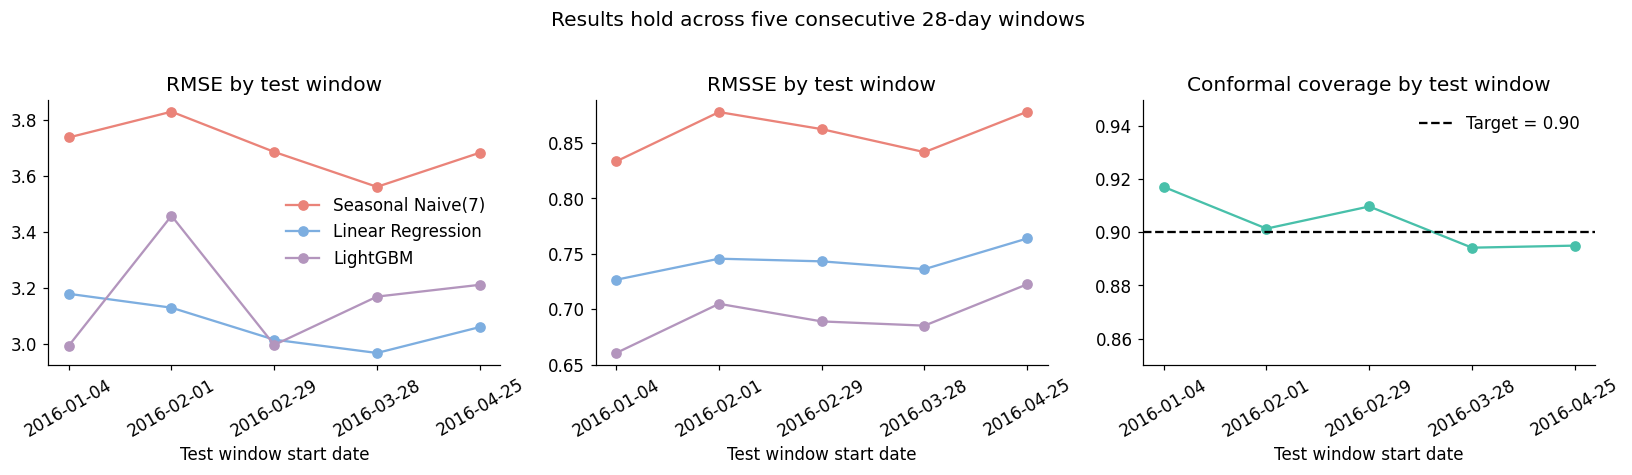

In [57]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
cvp = cv.sort_values("Test start date")
xl = [str(d) for d in cvp["Test start date"]]
for ax, metric in zip(axes[:2], ["RMSE", "RMSSE"]):
    for m, c in [("Naive", "Seasonal Naive(7)"), ("LinReg", "Linear Regression"), ("LightGBM", "LightGBM")]:
        ax.plot(xl, cvp[f"{metric} {m}"], marker="o", label=c, color=LINE_COLORS[c])
    ax.set_title(f"{metric} by test window"); ax.set_xlabel("Test window start date"); ax.tick_params(axis="x", rotation=30)
axes[0].legend(frameon=False)
axes[2].plot(xl, cvp["Conformal coverage"], marker="o", color="#48C0AA")
axes[2].axhline(0.90, color="black", linestyle="--", label="Target = 0.90")
axes[2].set_ylim(0.85, 0.95); axes[2].set_title("Conformal coverage by test window")
axes[2].set_xlabel("Test window start date"); axes[2].tick_params(axis="x", rotation=30); axes[2].legend(frameon=False)
fig.suptitle("Results hold across five consecutive 28-day windows", y=1.02)
plt.tight_layout(); plt.savefig("figures/fig10_rolling_validation.png", dpi=200, bbox_inches="tight"); plt.show()

---
## Part 8: Exploratory Extension - Volume-Based Model Router
**Idea:** Part 4 suggests LightGBM is better for low-volume products and linear regression for high-volume products. A *router* assigns each volume group to one of the two models.

Two variants are tested:
1. **Router chosen on the calibration window.** For each volume group, pick the model with the lower calibration RMSE. The test window is never used to make the choice, so this is the fair version.
2. **Fixed rule.** Low and mid volume use LightGBM, high volume uses linear regression. This rule was proposed *after* seeing earlier test results, so its score is optimistic.

**In our run:**

| Model | RMSE | MAE | RMSSE |
|---|---|---|---|
| LightGBM | 3.210 | 2.103 | 0.723 |
| Router (calibration) | 3.210 | 2.103 | 0.723 |
| Fixed rule | 3.030 | 1.896 | 0.717 |

The calibration-based router selected LightGBM in all groups, so it equals plain LightGBM. The fixed rule is best on all three metrics, but the gain over the best single model is small and has not been validated on independent data. We treat this as an idea for future work, not as a proven improvement.

In [58]:
# Volume groups from TRAINING data only (low / mid / high average sales)
item_mean = train.groupby("item_id").y.mean()
vgroup = pd.qcut(item_mean, 3, labels=["Low", "Mid", "High"])
calib["vol"] = calib.item_id.map(vgroup)
t_eval = t_eval.copy()
t_eval["vol"] = t_eval.item_id.map(vgroup)

# Router: for each volume group, choose the model with the lower RMSE on the CALIBRATION window
# (the test window is never used to choose the route)
route = {}
for grp, sub in calib.groupby("vol", observed=True):
    rmse_lr = np.sqrt(((sub.y - sub.pred_lr) ** 2).mean())
    rmse_gbm = np.sqrt(((sub.y - sub.pred_gbm) ** 2).mean())
    route[grp] = "pred_lr" if rmse_lr < rmse_gbm else "pred_gbm"
    print(f"{grp}: calibration RMSE  LinReg={rmse_lr:.3f}  LightGBM={rmse_gbm:.3f}  ->  {route[grp]}")

t_eval["pred_router"] = np.where(t_eval.vol.map(route) == "pred_lr", t_eval.pred_lr, t_eval.pred_gbm)

# Variant 2 (post-hoc rule): Low/Mid volume -> LightGBM, High volume -> Linear Regression.
# NOTE: this rule was inspired by the earlier test-window results, so its score is optimistic.
t_eval["pred_fixed"] = np.where(t_eval.vol == "High", t_eval.pred_lr, t_eval.pred_gbm)

out = pd.DataFrame({
    "Seasonal Naive(7)": evaluate(t_eval, "pred_naive"),
    "Linear Regression": evaluate(t_eval, "pred_lr"),
    "LightGBM": evaluate(t_eval, "pred_gbm"),
    "Router (chosen on calibration)": evaluate(t_eval, "pred_router"),
    "Fixed rule (Low/Mid GBM, High LR)": evaluate(t_eval, "pred_fixed"),
}).T
print(); print(out.round(3).to_string())
out.to_csv("router_results.csv")

Low: calibration RMSE  LinReg=1.360  LightGBM=1.224  ->  pred_gbm
Mid: calibration RMSE  LinReg=2.223  LightGBM=2.171  ->  pred_gbm
High: calibration RMSE  LinReg=4.986  LightGBM=4.908  ->  pred_gbm

                                    RMSE    MAE  RMSSE
Seasonal Naive(7)                  3.682  2.162  0.878
Linear Regression                  3.059  1.965  0.764
LightGBM                           3.210  2.103  0.723
Router (chosen on calibration)     3.210  2.103  0.723
Fixed rule (Low/Mid GBM, High LR)  3.030  1.896  0.717


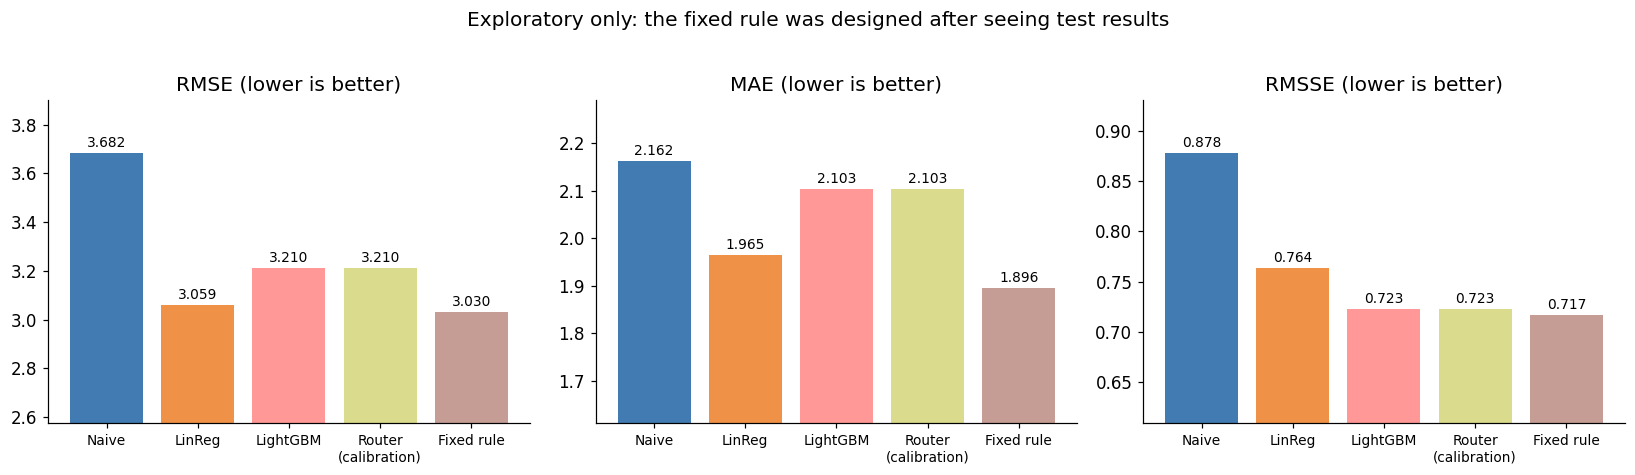

In [59]:
import numpy as np
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
pal = ["#427AB2", "#F09148", "#FF9896", "#DBDB8D", "#C59D94"]   # first 5 of the six-colour palette
labels = ["Naive", "LinReg", "LightGBM", "Router\n(calibration)", "Fixed rule"]
for ax, metric in zip(axes, ["RMSE", "MAE", "RMSSE"]):
    vals = out[metric].astype(float).values
    bars = ax.bar(labels, vals, color=pal)
    ax.bar_label(bars, fmt="%.3f", padding=2, fontsize=9)
    ax.set_title(metric + " (lower is better)")
    ax.set_ylim(vals.min() * 0.85, vals.max() * 1.06)
    ax.tick_params(axis="x", labelsize=9)
fig.suptitle("Exploratory only: the fixed rule was designed after seeing test results", y=1.02)
plt.tight_layout(); plt.savefig("figures/fig11_router.png", dpi=200, bbox_inches="tight"); plt.show()

---
## Summary and Limitations
### Main findings
1. Learned models clearly beat the seasonal-naive baseline, and this holds across five rolling windows.
2. No single model wins on every metric or in every product group: linear regression is stronger in RMSE and MAE (driven by high-volume items), LightGBM is stronger in RMSSE (every item counts equally).
3. Weekends and holidays are the hardest days to forecast.
4. Conformal intervals reach close to the 90% target (0.895 on the main test window, 0.903 on average over five windows) but are too narrow on weekends and holidays.
5. A higher service level always costs more overstock; the best stocking policy depends on the cost of a stock-out.

### Limitations
- One store and one department; results may not transfer to other stores.
- Anomalies are synthetic, so anomaly-detection scores are not real-world performance.
- The replenishment simulation ignores lead times and inventory carry-over, and its cost ratio is an assumption.
- Rolling windows cover only January to May 2016.
- The volume-based router was not validated on independent data.

### Future work
Per-scenario conformal calibration (weekends, holidays), a deep model such as N-HiTS with residual correction, per-item interval scales, and validation of the router on further time windows.

### Contributions of group members
- ZHOU Qimou (3375688): Problem Definition; Data sampling; Cleaning.
- SHEN Yang (3375860): Baseline/Light GBM models; Creative modules; Methodology.
- LI Haoliang (3375858): Anomaly detection; Inventory simulation; Results.
- SUN Wei (3375420): Feature engineering; Data visualization; Slide integration and conclusion.

### Use of generative AI
We acknowledge the use of Gemini (https://gemini.google.com/app) to generate the research framework for this group project. We entered the following prompts:"Analyze the requirements for the group assignment and help us develop a viable framework for the M5 data." The output from the Generative AI was adapted and modified for the final response.